<center><h1>Zuo_Xiyi_HW4</h1></center>
<br>
<center><font size="4">Time Series Classification Part 2: Binary and Multiclass Classification</font></center>

**Name:** Xiyi Zuo
**GitHub Username:** Kiera111
**USC ID:** 9330953458


### Package imports

All dependencies are imported together so the notebook can be run sequentially from a clean kernel.


In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    auc,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import StandardScaler, label_binarize

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 552
DATA_DIR = Path("../data/AReM")
SENSOR_COLUMNS = [
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23",
]
ACTIVITIES = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking",
]
BENDING = {"bending1", "bending2"}
TEST_DATASETS = {
    "bending1": {1, 2},
    "bending2": {1, 2},
    "cycling": {1, 2, 3},
    "lying": {1, 2, 3},
    "sitting": {1, 2, 3},
    "standing": {1, 2, 3},
    "walking": {1, 2, 3},
}
CHOSEN_STATS = ("mean", "std", "max")
L_VALUES = range(1, 21)
PLOT_SERIES = (1, 2, 6)


## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

Homework 3 already answered the research list, the bootstrap intervals, and the feature choice. This section keeps the code that Homework 4 needs: read the AReM files, apply the same train/test split, and build the time-domain features. The three features retained from Homework 3 are the **mean**, the **standard deviation**, and the **maximum**.

### (a) Obtain Data

The files are read from `../data/AReM`. Comment lines are skipped. `bending2/dataset4.csv` is space-separated, two cycling files have a trailing comma, and `sitting/dataset8.csv` has 479 rows rather than 480. Those rows are kept.


In [2]:
def load_instance(path):
    rows = []
    issues = set()
    for line_number, raw_line in enumerate(
        path.read_text(encoding="utf-8", errors="replace").splitlines(),
        start=1,
    ):
        line = raw_line.strip()
        if not line or line.startswith("#"):
            continue
        if "," in line:
            if line.endswith(","):
                issues.add("trailing comma")
            parts = [part.strip() for part in line.split(",") if part.strip() != ""]
        else:
            issues.add("whitespace separator")
            parts = line.split()
        if len(parts) < 7:
            raise ValueError(f"{path} line {line_number} does not have 7 fields")
        rows.append([float(part) for part in parts[:7]])
    frame = pd.DataFrame(rows, columns=["time", *SENSOR_COLUMNS])
    if len(frame) != 480:
        issues.add(f"{len(frame)} samples")
    return frame, sorted(issues)


instances = []
cleaning_rows = []
for activity in ACTIVITIES:
    paths = sorted(
        (DATA_DIR / activity).glob("dataset*.csv"),
        key=lambda path: int(path.stem.replace("dataset", "")),
    )
    for path in paths:
        dataset_id = int(path.stem.replace("dataset", ""))
        series, issues = load_instance(path)
        instances.append(
            {
                "activity": activity,
                "dataset": dataset_id,
                "series": series,
            }
        )
        if issues:
            cleaning_rows.append(
                {
                    "file": path.relative_to(DATA_DIR).as_posix(),
                    "cleaning": ", ".join(issues),
                }
            )

print(f"Loaded {len(instances)} instances from {DATA_DIR.as_posix()}")
display(pd.DataFrame(cleaning_rows))


Loaded 88 instances from ../data/AReM


,file,cleaning
0,bending2/dataset4.csv,whitespace separator
1,cycling/dataset9.csv,trailing comma
2,cycling/dataset14.csv,trailing comma
3,sitting/dataset8.csv,479 samples


### (b) Splitting Data

Datasets 1 and 2 in `bending1` and `bending2`, and datasets 1, 2, and 3 in the other folders, are the test set. The remaining files are the training set. Bending is the union of `bending1` and `bending2`. Every other activity is the negative class for the binary problem.


In [3]:
for item in instances:
    item["split"] = "test" if item["dataset"] in TEST_DATASETS[item["activity"]] else "train"
    item["bending"] = int(item["activity"] in BENDING)

train_items = [item for item in instances if item["split"] == "train"]
test_items = [item for item in instances if item["split"] == "test"]
y_train_bin = np.array([item["bending"] for item in train_items])
y_test_bin = np.array([item["bending"] for item in test_items])
y_train_act = np.array([item["activity"] for item in train_items])
y_test_act = np.array([item["activity"] for item in test_items])

split_table = (
    pd.DataFrame(
        {
            "activity": [item["activity"] for item in instances],
            "split": [item["split"] for item in instances],
        }
    )
    .groupby(["activity", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=ACTIVITIES, columns=["train", "test"])
)
split_table.loc["total"] = split_table.sum()
display(split_table.astype(int))
print(
    f"Binary training counts: bending = {int(y_train_bin.sum())}, "
    f"other = {int((y_train_bin == 0).sum())}"
)


split,train,test
activity,,
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3
total,69,19


Binary training counts: bending = 9, other = 60


### (c) Feature Extraction

Each series is broken into `l` approximately equal pieces. For every piece the notebook keeps the mean, the sample standard deviation, and the maximum. With all six series this produces `18l` features. The scatter plots later use only series 1, 2, and 6, which are `avg_rss12`, `var_rss12`, and `var_rss23`.


In [4]:
def column_names(l, series_ids=range(1, 7)):
    names = []
    for series_id in series_ids:
        for part in range(1, l + 1):
            for stat in CHOSEN_STATS:
                names.append(f"{stat}_s{series_id}_p{part}")
    return names


def instance_feature_row(series, l):
    values = []
    for column in SENSOR_COLUMNS:
        observations = series[column].to_numpy(dtype=float)
        edges = np.linspace(0, len(observations), l + 1, dtype=int)
        for start, stop in zip(edges[:-1], edges[1:]):
            segment = observations[start:stop]
            values.extend(
                [
                    float(segment.mean()),
                    float(segment.std(ddof=1)),
                    float(segment.max()),
                ]
            )
    return values


def feature_matrix(items, l):
    return np.vstack([instance_feature_row(item["series"], l) for item in items])


feature_cache = {}
for segment_count in L_VALUES:
    feature_cache[segment_count] = {
        "train": feature_matrix(train_items, segment_count),
        "test": feature_matrix(test_items, segment_count),
        "columns": column_names(segment_count),
    }

preview = pd.DataFrame(
    feature_cache[1]["train"],
    columns=feature_cache[1]["columns"],
)
preview.insert(0, "activity", y_train_act)
preview.insert(1, "bending", y_train_bin)
print("Training feature matrix at l = 1:", feature_cache[1]["train"].shape)
print("Any missing values:", bool(np.isnan(feature_cache[1]["train"]).any()))
display(preview.head())


Training feature matrix at l = 1: (69, 18)
Any missing values: False


,activity,bending,mean_s1_p1,std_s1_p1,max_s1_p1,mean_s2_p1,std_s2_p1,max_s2_p1,mean_s3_p1,std_s3_p1,max_s3_p1,mean_s4_p1,std_s4_p1,max_s4_p1,mean_s5_p1,std_s5_p1,max_s5_p1,mean_s6_p1,std_s6_p1,max_s6_p1
0,bending1,1,43.9545,1.5588,47.40,0.4263,0.3387,1.70,22.1224,3.0309,29.75,0.4973,0.5507,4.44,35.5885,1.9996,38.50,0.4933,0.5135,1.79
1,bending1,1,42.1798,3.6707,47.75,0.6960,0.6309,3.00,22.1836,3.8105,30.00,0.9899,0.9537,5.15,33.4939,3.8494,38.67,0.6135,0.5243,2.18
2,bending1,1,41.6781,2.2435,45.75,0.5360,0.4055,2.83,19.0066,4.0871,28.25,0.8419,0.9288,6.42,29.8571,2.4110,37.50,0.3833,0.3892,1.79
3,bending1,1,43.4550,1.3861,48.00,0.3781,0.3156,1.58,15.7933,3.8476,27.00,0.8494,0.9958,10.03,23.0348,2.4889,33.50,0.6796,0.6225,5.26
4,bending1,1,43.9691,1.6184,48.00,0.4131,0.2631,1.50,15.8680,3.7424,26.33,0.6664,0.7890,5.17,22.1038,3.3183,30.75,0.5553,0.4878,2.96


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

The training instances are plotted with the mean, standard deviation, and maximum of time series 1, 2, and 6. Blue points are bending and orange points are the other activities.


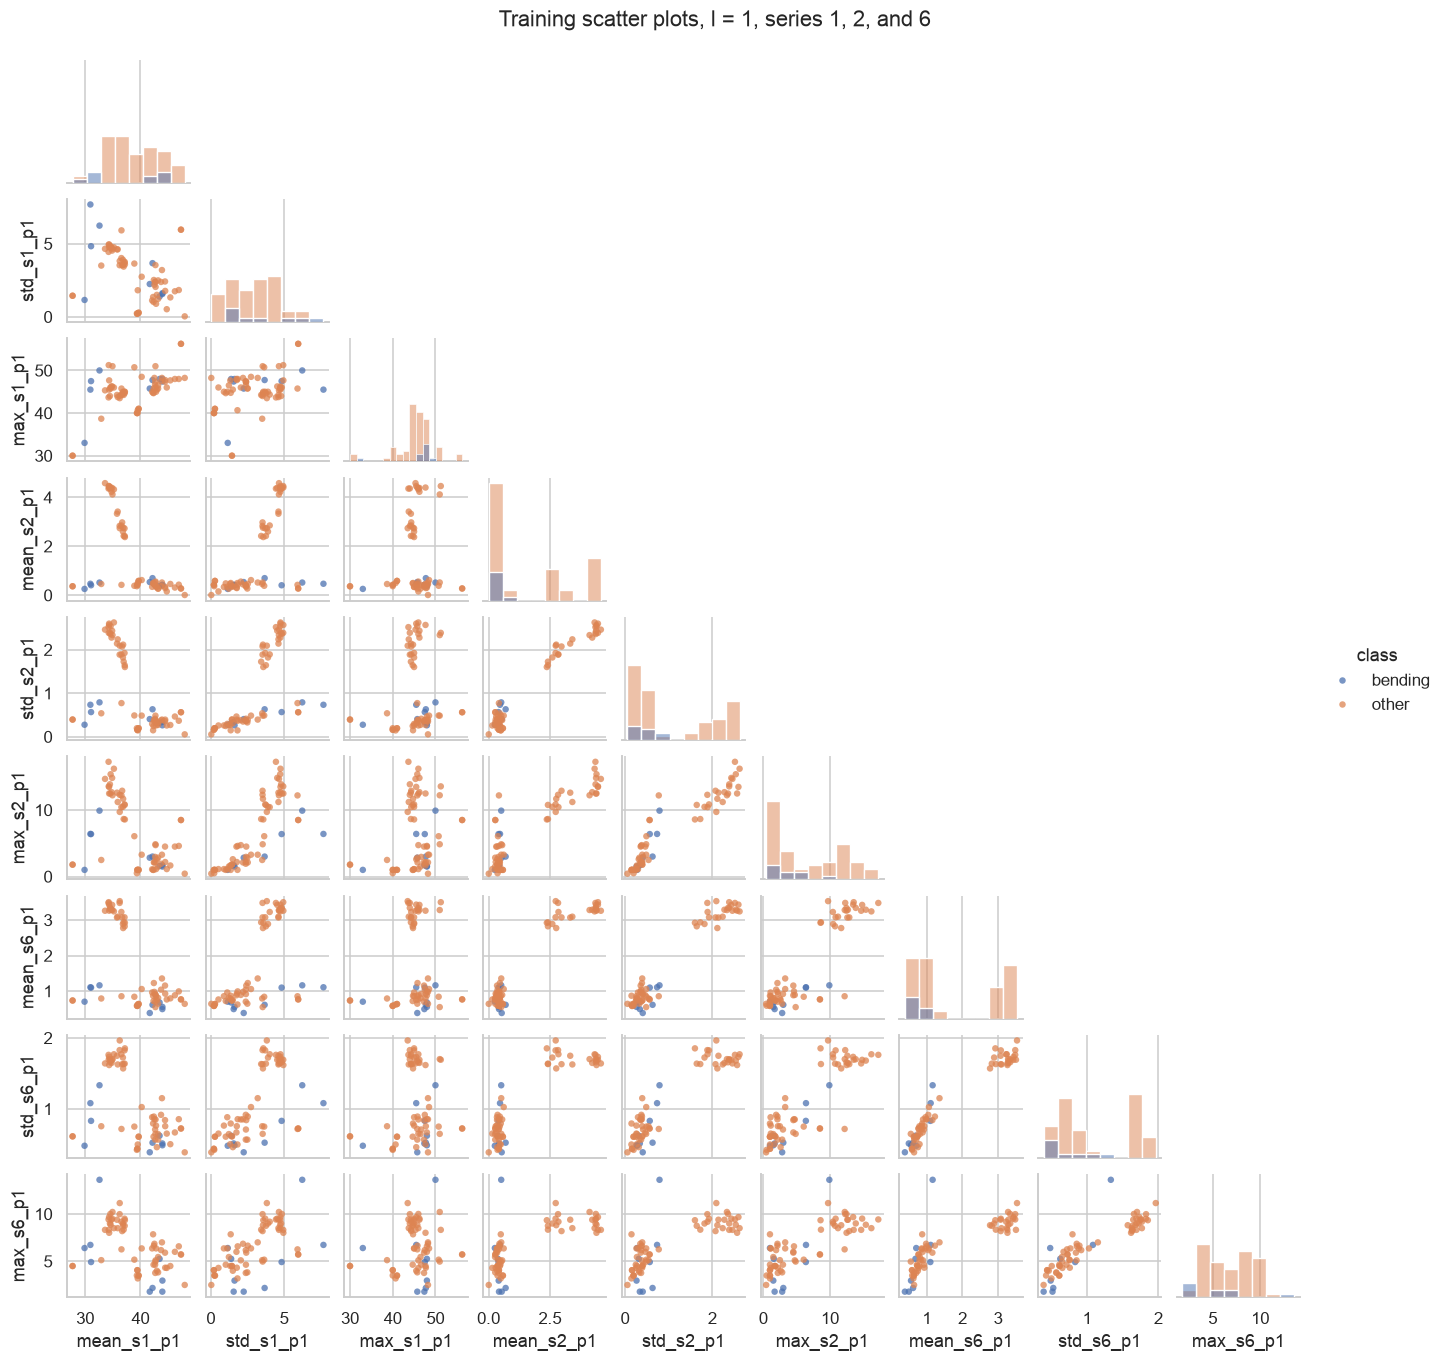

In [5]:
def plot_feature_frame(segment_count, title):
    frame = pd.DataFrame(
        feature_cache[segment_count]["train"],
        columns=feature_cache[segment_count]["columns"],
    )
    kept = [
        name
        for name in frame.columns
        if any(f"_s{series_id}_" in name for series_id in PLOT_SERIES)
    ]
    frame = frame[kept].copy()
    frame["class"] = np.where(y_train_bin == 1, "bending", "other")
    grid = sns.pairplot(
        frame,
        hue="class",
        hue_order=["bending", "other"],
        corner=True,
        diag_kind="hist",
        height=1.35,
        plot_kws={"alpha": 0.75, "s": 18, "edgecolor": "none"},
    )
    grid.fig.suptitle(title, y=1.02)
    plt.show()
    return kept


plot_columns_l1 = plot_feature_frame(
    1,
    "Training scatter plots, l = 1, series 1, 2, and 6",
)


#### ii. Splitted Plots

Each training series is split into two pieces of equal length, so series 1, 2, and 6 now contribute two copies of each selected feature. The same scatter-plot comparison is repeated on those 18 features.


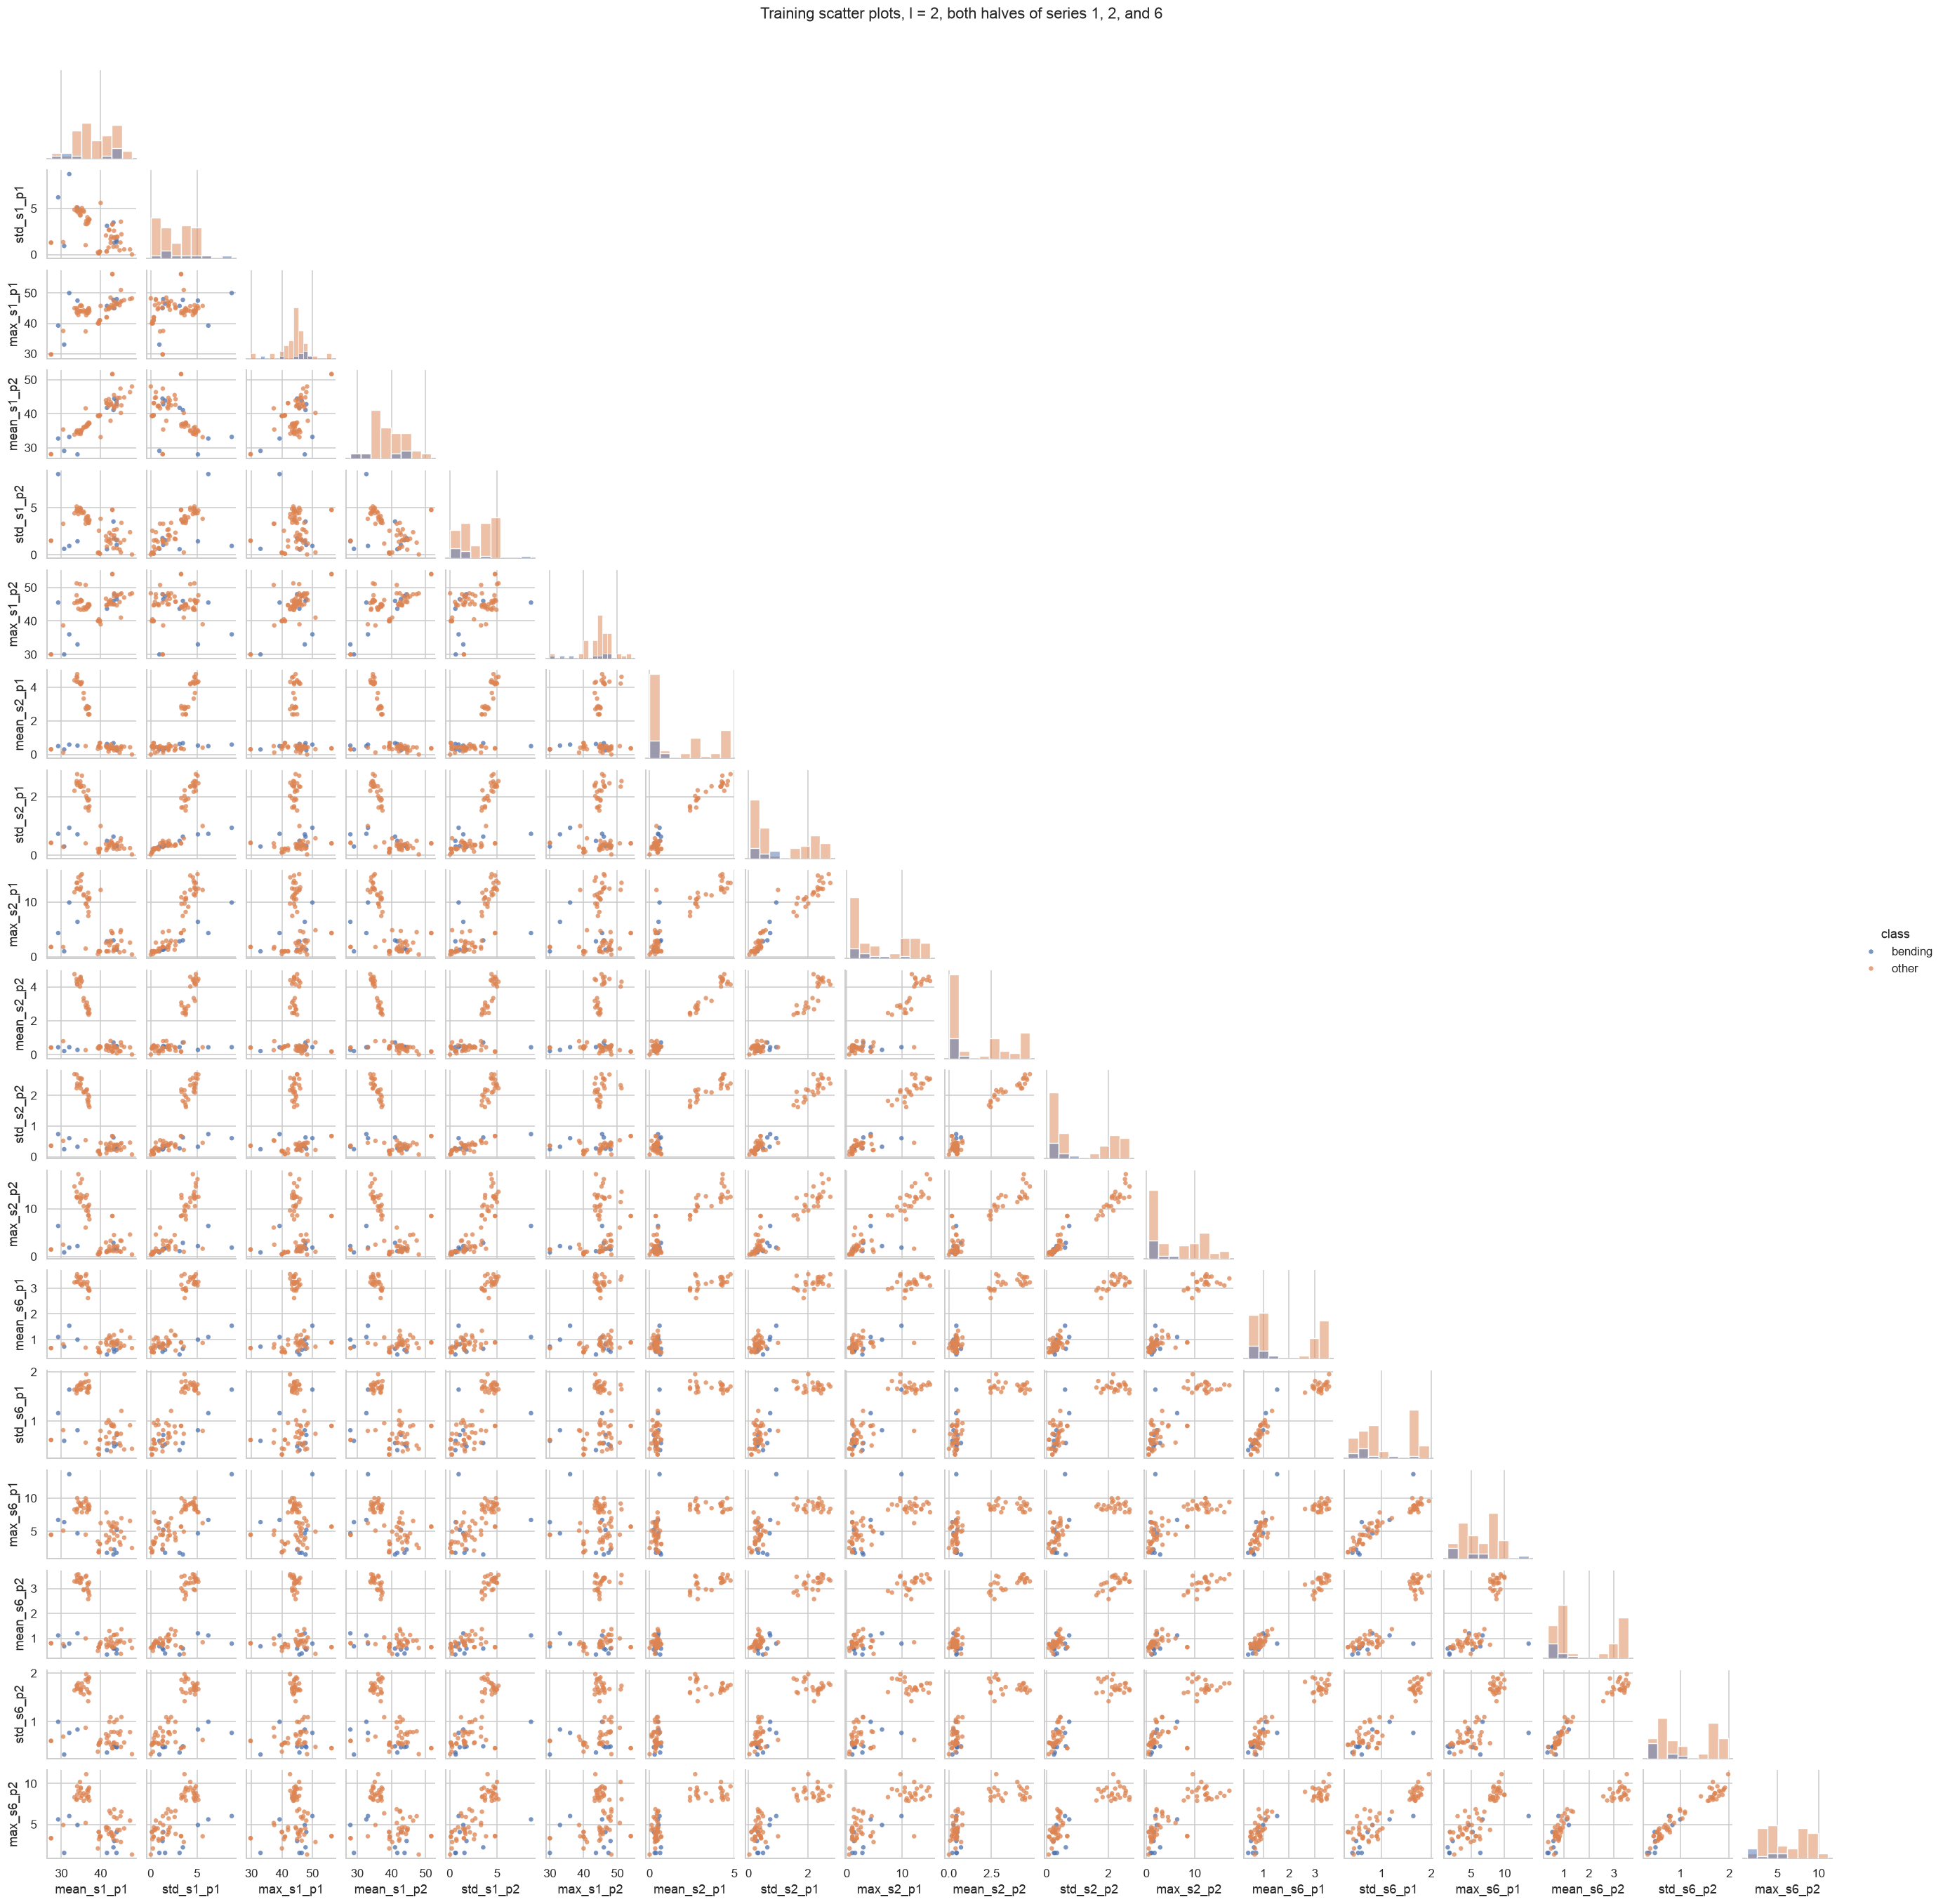

Training accuracy using the plotted l = 1 features: 0.9565
Training accuracy using the plotted l = 2 features: 1.0000
There is no considerable difference. Bending stays in the tighter group and the other activities stay more spread out. Splitting each series in half adds a second set of the same three summaries, but it does not change which class separates.


In [6]:
plot_columns_l2 = plot_feature_frame(
    2,
    "Training scatter plots, l = 2, both halves of series 1, 2, and 6",
)


def training_accuracy(columns, segment_count):
    frame = pd.DataFrame(
        feature_cache[segment_count]["train"],
        columns=feature_cache[segment_count]["columns"],
    )
    model = LogisticRegression(C=np.inf, solver="lbfgs", max_iter=200)
    model.fit(frame[columns], y_train_bin)
    return accuracy_score(y_train_bin, model.predict(frame[columns]))


accuracy_l1 = training_accuracy(plot_columns_l1, 1)
accuracy_l2 = training_accuracy(plot_columns_l2, 2)
print(f"Training accuracy using the plotted l = 1 features: {accuracy_l1:.4f}")
print(f"Training accuracy using the plotted l = 2 features: {accuracy_l2:.4f}")
if abs(accuracy_l1 - accuracy_l2) < 0.05:
    print(
        "There is no considerable difference. Bending stays in the tighter group "
        "and the other activities stay more spread out. Splitting each series in half "
        "adds a second set of the same three summaries, but it does not change which class separates."
    )
else:
    print(
        "Splitting the series does change the picture. The training accuracy of a "
        "logistic regression fit to the plotted features moves by more than 0.05, "
        "so the two halves are not just repeating the l = 1 scatter plots."
    )


#### iii. Time Series Segments

For each \(l \in \{1, 2, \ldots, 20\}\), all six series are broken into \(l\) pieces and the three selected features are computed on every piece. The classifier is logistic regression without a penalty (`C = inf`). `RFE` chooses how many of those features to keep.

The number of features changes with \(l\), so the cross-validation has to score the whole selection procedure.

- The wrong way is to run `RFE` once on the entire training set, freeze the selected columns, and only then cross-validate the logistic regression. The validation folds have already influenced the selected features, so the cross-validation accuracy is too optimistic.
- The right way, used here, builds the features for a given \(l\) before the split, because that step does not use the labels. Inside each training fold it runs `RFE`, fits logistic regression on the selected columns, and scores the fold that was held out. The score for each pair \((l, p)\) is the mean of those five folds.

There are only nine bending instances in the training set, so a plain fold can miss that class. Stratified 5-fold cross-validation keeps bending represented in every fold. One `RFE` ranking is fit in each fold; feature \(p\) is the prefix of that ranking, which is the subset `RFE` would keep if it stopped at \(p\) features.


In [7]:
binary_folds = list(
    StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(
        feature_cache[1]["train"],
        y_train_bin,
    )
)


def logistic_model():
    return LogisticRegression(C=np.inf, solver="lbfgs", max_iter=100)


def cross_validate_l(segment_count, folds):
    matrix = feature_cache[segment_count]["train"]
    n_features = matrix.shape[1]
    fold_scores = np.zeros((len(folds), n_features))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        warnings.simplefilter("ignore", RuntimeWarning)
        for fold_number, (train_index, valid_index) in enumerate(folds):
            ranking_model = RFE(logistic_model(), n_features_to_select=1, step=1)
            ranking_model.fit(matrix[train_index], y_train_bin[train_index])
            order = np.argsort(ranking_model.ranking_)
            for feature_count in range(1, n_features + 1):
                columns = order[:feature_count]
                model = logistic_model()
                model.fit(matrix[train_index][:, columns], y_train_bin[train_index])
                predicted = model.predict(matrix[valid_index][:, columns])
                fold_scores[fold_number, feature_count - 1] = accuracy_score(
                    y_train_bin[valid_index],
                    predicted,
                )
    mean_scores = fold_scores.mean(axis=0)
    best_feature_count = int(np.argmax(mean_scores) + 1)
    return best_feature_count, float(mean_scores[best_feature_count - 1])


selection_rows = []
best_l = None
best_p = None
best_cv_accuracy = -1.0
for segment_count in L_VALUES:
    feature_count, cv_accuracy = cross_validate_l(segment_count, binary_folds)
    selection_rows.append(
        {
            "l": segment_count,
            "p": feature_count,
            "features available": 18 * segment_count,
            "CV accuracy": cv_accuracy,
        }
    )
    print(f"l = {segment_count:2d}  best p = {feature_count:3d}  CV accuracy = {cv_accuracy:.4f}")
    if cv_accuracy > best_cv_accuracy:
        best_l = segment_count
        best_p = feature_count
        best_cv_accuracy = cv_accuracy

selection_table = pd.DataFrame(selection_rows)
display(selection_table)
print(f"Selected pair: l = {best_l}, p = {best_p}, CV accuracy = {best_cv_accuracy:.4f}")


l =  1  best p =   5  CV accuracy = 0.9571


l =  2  best p =   7  CV accuracy = 0.9571


l =  3  best p =   1  CV accuracy = 0.9714


l =  4  best p =   2  CV accuracy = 0.9714


l =  5  best p =  83  CV accuracy = 0.9714


...

l = 18  best p =  51  CV accuracy = 0.9857


l = 19  best p =  98  CV accuracy = 0.9857


l = 20  best p =  21  CV accuracy = 0.9714


,l,p,features available,CV accuracy
0,1,5,18,0.9571
1,2,7,36,0.9571
2,3,1,54,0.9714
3,4,2,72,0.9714
4,5,83,90,0.9714
5,6,5,108,0.9714
6,7,8,126,0.9714
7,8,4,144,0.9714
8,9,27,162,0.9857
9,10,15,180,0.9714


Selected pair: l = 9, p = 27, CV accuracy = 0.9857


#### iv. Confusion Matrix

The selected pair is refit on the full training set. `RFE` prunes the features, logistic regression is fit without a penalty, and `statsmodels` supplies the coefficients and p-values. The confusion matrix, ROC curve, and AUC below are computed on the training set.


Selected features:
max_s1_p5, mean_s1_p6, max_s1_p6, mean_s1_p7, max_s1_p7, max_s2_p3, mean_s3_p2, mean_s3_p3, mean_s3_p7, mean_s3_p8, mean_s5_p1, max_s5_p1, mean_s5_p2, max_s5_p2, mean_s5_p3, max_s5_p3, mean_s5_p4, mean_s5_p5, max_s5_p5, mean_s5_p6, mean_s5_p8, mean_s5_p9, max_s6_p3, max_s6_p5, max_s6_p7, max_s6_p8, max_s6_p9
Largest absolute coefficient: 0.5652
Final logistic regression converged: True


,feature,sklearn coefficient,statsmodels coefficient,p-value
0,intercept,-0.0162,24.6888,1.0
1,max_s1_p5,-0.3716,0.4596,1.0
2,mean_s1_p6,-0.3562,-5.5896,1.0
3,max_s1_p6,-0.4333,-0.3165,1.0
4,mean_s1_p7,-0.2793,-0.9700,1.0
5,max_s1_p7,-0.3933,2.8085,1.0
6,max_s2_p3,-0.3176,-3.4942,1.0
7,mean_s3_p2,-0.2500,0.9287,1.0
8,mean_s3_p3,-0.2185,-1.3459,1.0
9,mean_s3_p7,0.2181,2.0574,1.0


statsmodels converged: False
The classes are perfectly separated on the training set, so the unpenalized likelihood does not have a finite maximum. statsmodels therefore does not identify the p-values; they come back as 1. The sklearn fit stops at max_iter = 100, which is the early stop suggested for this instability, and those coefficients are the ones used for the confusion matrix and ROC.


,pred other,pred bending
actual other,60,0
actual bending,0,9


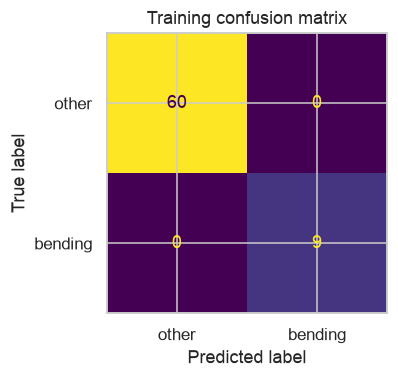

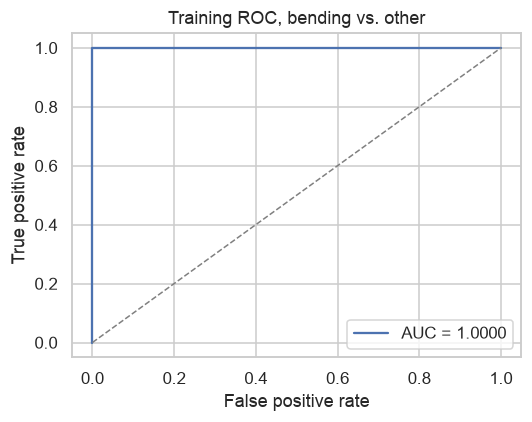

Training accuracy: 1.0000
Training AUC: 1.0000


In [8]:
train_matrix = feature_cache[best_l]["train"]
test_matrix = feature_cache[best_l]["test"]
feature_names = np.array(feature_cache[best_l]["columns"])

with warnings.catch_warnings(record=True) as final_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    selector = RFE(logistic_model(), n_features_to_select=best_p, step=1)
    selector.fit(train_matrix, y_train_bin)
final_converged = not any(
    issubclass(item.category, ConvergenceWarning) for item in final_warnings
)
selected_mask = selector.support_
selected_names = feature_names[selected_mask]
train_selected = train_matrix[:, selected_mask]
test_selected = test_matrix[:, selected_mask]
final_model = selector.estimator_
train_probability = final_model.predict_proba(train_selected)[:, 1]
train_prediction = final_model.predict(train_selected)

print("Selected features:")
print(", ".join(selected_names))
print(f"Largest absolute coefficient: {np.max(np.abs(final_model.coef_)):.4f}")
print(f"Final logistic regression converged: {final_converged}")

try:
    logit = sm.Logit(y_train_bin, sm.add_constant(train_selected, has_constant="add"))
    with warnings.catch_warnings(record=True) as logit_warnings:
        warnings.simplefilter("always")
        logit_result = logit.fit(disp=False, maxiter=200)
    parameter_table = pd.DataFrame(
        {
            "feature": ["intercept", *selected_names],
            "sklearn coefficient": np.r_[final_model.intercept_, final_model.coef_.ravel()],
            "statsmodels coefficient": logit_result.params,
            "p-value": logit_result.pvalues,
        }
    )
    display(parameter_table)
    statsmodels_converged = bool(logit_result.mle_retvals.get("converged", True))
    perfect_separation = any("Perfect separation" in str(item.message) for item in logit_warnings)
    print(f"statsmodels converged: {statsmodels_converged}")
    if perfect_separation or not statsmodels_converged:
        print(
            "The classes are perfectly separated on the training set, so the "
            "unpenalized likelihood does not have a finite maximum. statsmodels "
            "therefore does not identify the p-values; they come back as 1. "
            "The sklearn fit stops at max_iter = 100, which is the early stop "
            "suggested for this instability, and those coefficients are the ones "
            "used for the confusion matrix and ROC."
        )
except Exception as error:
    statsmodels_converged = False
    print(f"statsmodels did not return p-values: {error}")
    display(
        pd.DataFrame(
            {
                "feature": ["intercept", *selected_names],
                "coefficient": np.r_[final_model.intercept_, final_model.coef_.ravel()],
            }
        )
    )

train_confusion = confusion_matrix(y_train_bin, train_prediction, labels=[0, 1])
display(pd.DataFrame(train_confusion, index=["actual other", "actual bending"], columns=["pred other", "pred bending"]))
fig, axis = plt.subplots(figsize=(4.2, 3.6))
ConfusionMatrixDisplay(train_confusion, display_labels=["other", "bending"]).plot(ax=axis, colorbar=False)
axis.set_title("Training confusion matrix")
fig.tight_layout()
plt.show()

false_positive, true_positive, _ = roc_curve(y_train_bin, train_probability)
train_auc = auc(false_positive, true_positive)
fig, axis = plt.subplots(figsize=(5, 4))
axis.plot(false_positive, true_positive, label=f"AUC = {train_auc:.4f}")
axis.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
axis.set_xlabel("False positive rate")
axis.set_ylabel("True positive rate")
axis.set_title("Training ROC, bending vs. other")
axis.legend(loc="lower right")
fig.tight_layout()
plt.show()
print(f"Training accuracy: {accuracy_score(y_train_bin, train_prediction):.4f}")
print(f"Training AUC: {train_auc:.4f}")


#### v. Test Classifier

The test series are broken into the same number of pieces as the training series. The classifier uses only the features that `RFE` kept on the training set.


In [9]:
test_probability = final_model.predict_proba(test_selected)[:, 1]
test_prediction = final_model.predict(test_selected)
test_accuracy = accuracy_score(y_test_bin, test_prediction)
test_confusion = confusion_matrix(y_test_bin, test_prediction, labels=[0, 1])
display(pd.DataFrame(test_confusion, index=["actual other", "actual bending"], columns=["pred other", "pred bending"]))
false_positive, true_positive, _ = roc_curve(y_test_bin, test_probability)
test_auc = auc(false_positive, true_positive)
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test AUC: {test_auc:.4f}")
print(f"Cross-validation accuracy: {best_cv_accuracy:.4f}")
print(f"Test accuracy minus CV accuracy: {test_accuracy - best_cv_accuracy:.4f}")
if test_accuracy + 0.02 < best_cv_accuracy:
    print(
        "The test accuracy is lower than the cross-validation accuracy. "
        "The training set has only nine bending instances, so the selected model still overfits somewhat."
    )
elif test_accuracy > best_cv_accuracy + 0.02:
    print(
        "The test accuracy is higher than the cross-validation accuracy. "
        "With only 19 test instances, that gap can come from the particular test split."
    )
else:
    print("The test accuracy is close to the cross-validation accuracy.")


,pred other,pred bending
actual other,15,0
actual bending,0,4


Test accuracy: 1.0000
Test AUC: 1.0000
Cross-validation accuracy: 0.9857
Test accuracy minus CV accuracy: 0.0143
The test accuracy is close to the cross-validation accuracy.


#### vi. Separation

A well-separated pair of classes makes the unpenalized logistic coefficients diverge, and the solver fails to converge. The fit above is the evidence for this training set.


In [10]:
largest_coefficient = float(np.max(np.abs(np.r_[final_model.intercept_, final_model.coef_.ravel()])))
print(f"Largest absolute sklearn coefficient: {largest_coefficient:.4f}")
print(f"sklearn converged: {final_converged}")
print(f"statsmodels converged: {statsmodels_converged}")
if (not final_converged) or (not statsmodels_converged) or largest_coefficient > 30:
    print(
        "Yes. The training predictions are perfect, and statsmodels reports perfect "
        "separation. The unpenalized maximum likelihood estimate does not settle on "
        "a finite coefficient vector, which is the instability caused by well-separated "
        "classes. Stopping sklearn at max_iter = 100 keeps the coefficients used for "
        "classification finite."
    )
else:
    print(
        "No. The unpenalized fit converges and the coefficients stay moderate, "
        "so the classes are not separated so cleanly that the logistic regression becomes unstable."
    )


Largest absolute sklearn coefficient: 0.5652
sklearn converged: True
statsmodels converged: False
Yes. The training predictions are perfect, and statsmodels reports perfect separation. The unpenalized maximum likelihood estimate does not settle on a finite coefficient vector, which is the instability caused by well-separated classes. Stopping sklearn at max_iter = 100 keeps the coefficients used for classification finite.


#### vii. Imbalance

The training set has 9 bending instances and 60 other instances, so the classes are imbalanced. Case-control sampling keeps every bending instance and draws an equal number of other instances. Logistic regression is fit on that balanced sample with the features already selected in (a)iii.

The slopes stay as fit on the balanced sample. The intercept is shifted back to the training prevalence \(\pi = 9/69\):

\[
\beta_0^{\text{corrected}} = \beta_0^{\text{sample}} + \log\frac{\pi}{1-\pi} - \log\frac{0.5}{0.5}.
\]

The second logarithm is zero because the case-control sample is balanced. The confusion matrix, ROC, and AUC use the corrected probabilities on the full training set.


Balanced sample size: 18 (9 bending, 9 other)
Sample intercept: -0.0067
Corrected intercept: -1.9038
Yes, the classes are imbalanced. A model trained on the raw training set mostly sees the other class, so the case-control fit estimates the slopes on equal class counts and the intercept is then corrected to the training prevalence.


,pred other,pred bending
actual other,60,0
actual bending,0,9


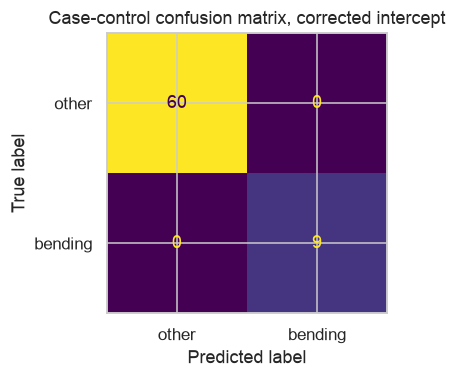

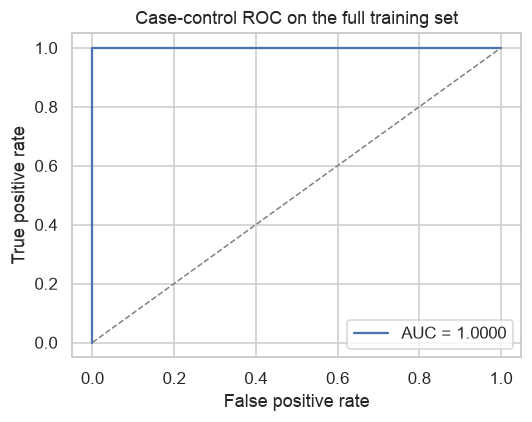

Corrected training accuracy: 1.0000
Corrected training AUC: 1.0000


In [11]:
bending_index = np.flatnonzero(y_train_bin == 1)
other_index = np.flatnonzero(y_train_bin == 0)
sampled_other = np.random.default_rng(RANDOM_STATE).choice(
    other_index,
    size=len(bending_index),
    replace=False,
)
sample_index = np.concatenate([bending_index, sampled_other])
sample_model = logistic_model()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    sample_model.fit(train_selected[sample_index], y_train_bin[sample_index])

pi_bending = float(y_train_bin.mean())
intercept_adjustment = np.log(pi_bending / (1.0 - pi_bending))
corrected_score = sample_model.decision_function(train_selected) + intercept_adjustment
corrected_probability = 1.0 / (1.0 + np.exp(-corrected_score))
corrected_prediction = (corrected_probability >= 0.5).astype(int)

print(f"Balanced sample size: {len(sample_index)} ({len(bending_index)} bending, {len(bending_index)} other)")
print(f"Sample intercept: {float(sample_model.intercept_[0]):.4f}")
print(f"Corrected intercept: {float(sample_model.intercept_[0] + intercept_adjustment):.4f}")
print(
    "Yes, the classes are imbalanced. A model trained on the raw training set "
    "mostly sees the other class, so the case-control fit estimates the slopes on "
    "equal class counts and the intercept is then corrected to the training prevalence."
)

corrected_confusion = confusion_matrix(y_train_bin, corrected_prediction, labels=[0, 1])
display(
    pd.DataFrame(
        corrected_confusion,
        index=["actual other", "actual bending"],
        columns=["pred other", "pred bending"],
    )
)
fig, axis = plt.subplots(figsize=(4.2, 3.6))
ConfusionMatrixDisplay(corrected_confusion, display_labels=["other", "bending"]).plot(ax=axis, colorbar=False)
axis.set_title("Case-control confusion matrix, corrected intercept")
fig.tight_layout()
plt.show()

false_positive, true_positive, _ = roc_curve(y_train_bin, corrected_probability)
corrected_auc = auc(false_positive, true_positive)
fig, axis = plt.subplots(figsize=(5, 4))
axis.plot(false_positive, true_positive, label=f"AUC = {corrected_auc:.4f}")
axis.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
axis.set_xlabel("False positive rate")
axis.set_ylabel("True positive rate")
axis.set_title("Case-control ROC on the full training set")
axis.legend(loc="lower right")
fig.tight_layout()
plt.show()
print(f"Corrected training accuracy: {accuracy_score(y_train_bin, corrected_prediction):.4f}")
print(f"Corrected training AUC: {corrected_auc:.4f}")


### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

The same values of \(l\) are searched again. Instead of choosing \(p\) with `RFE`, the model uses an L1 penalty. `liblinear` fits the binary L1 problem. Features are standardized inside each fold, and the inverse penalty \(C\) is chosen by the same stratified folds. The pair \((l, C)\) with the highest cross-validation accuracy is refit on the full training set and then scored on the test set.


In [12]:
binary_penalties = np.logspace(-3, 3, 13)


def cross_validate_l1(segment_count, labels, folds, solver, penalties, max_iter):
    matrix = feature_cache[segment_count]["train"]
    fold_scores = np.zeros((len(folds), len(penalties)))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        for fold_number, (train_index, valid_index) in enumerate(folds):
            scaler = StandardScaler().fit(matrix[train_index])
            train_scaled = scaler.transform(matrix[train_index])
            valid_scaled = scaler.transform(matrix[valid_index])
            for penalty_index, penalty in enumerate(penalties):
                model = LogisticRegression(
                    solver=solver,
                    l1_ratio=1.0,
                    C=float(penalty),
                    max_iter=max_iter,
                    tol=1e-3,
                    random_state=RANDOM_STATE,
                )
                model.fit(train_scaled, labels[train_index])
                predicted = model.predict(valid_scaled)
                fold_scores[fold_number, penalty_index] = accuracy_score(
                    labels[valid_index],
                    predicted,
                )
    mean_scores = fold_scores.mean(axis=0)
    best_index = int(np.argmax(mean_scores))
    return float(penalties[best_index]), float(mean_scores[best_index])


l1_rows = []
best_l1_l = None
best_l1_c = None
best_l1_cv = -1.0
for segment_count in L_VALUES:
    penalty, cv_accuracy = cross_validate_l1(
        segment_count,
        y_train_bin,
        binary_folds,
        solver="liblinear",
        penalties=binary_penalties,
        max_iter=200,
    )
    l1_rows.append({"l": segment_count, "C": penalty, "CV accuracy": cv_accuracy})
    print(f"l = {segment_count:2d}  best C = {penalty:.4g}  CV accuracy = {cv_accuracy:.4f}")
    if cv_accuracy > best_l1_cv:
        best_l1_l = segment_count
        best_l1_c = penalty
        best_l1_cv = cv_accuracy

display(pd.DataFrame(l1_rows))
print(f"Selected L1 pair: l = {best_l1_l}, C = {best_l1_c:.4g}, CV accuracy = {best_l1_cv:.4f}")

l1_scaler = StandardScaler().fit(feature_cache[best_l1_l]["train"])
l1_model = LogisticRegression(
    solver="liblinear",
    l1_ratio=1.0,
    C=best_l1_c,
    max_iter=200,
    random_state=RANDOM_STATE,
)
l1_model.fit(l1_scaler.transform(feature_cache[best_l1_l]["train"]), y_train_bin)
l1_test_prediction = l1_model.predict(l1_scaler.transform(feature_cache[best_l1_l]["test"]))
l1_test_accuracy = accuracy_score(y_test_bin, l1_test_prediction)
nonzero_coefficients = int(np.sum(np.abs(l1_model.coef_) > 1e-8))
print(f"L1 test accuracy: {l1_test_accuracy:.4f}")
print(f"Nonzero coefficients, excluding the intercept: {nonzero_coefficients}")


l =  1  best C = 0.3162  CV accuracy = 0.9714
l =  2  best C = 0.3162  CV accuracy = 0.9429


l =  3  best C = 0.3162  CV accuracy = 0.9714
l =  4  best C = 1  CV accuracy = 0.9571


l =  5  best C = 0.3162  CV accuracy = 0.9286


l =  6  best C = 31.62  CV accuracy = 0.9429
l =  7  best C = 10  CV accuracy = 0.9571


l =  8  best C = 316.2  CV accuracy = 0.9714
l =  9  best C = 0.3162  CV accuracy = 0.9132


...

l = 18  best C = 3.162  CV accuracy = 0.9714


l = 19  best C = 3.162  CV accuracy = 0.9714


l = 20  best C = 1  CV accuracy = 0.9571


,l,C,CV accuracy
0,1,0.3162,0.9714
1,2,0.3162,0.9429
2,3,0.3162,0.9714
3,4,1.0000,0.9571
4,5,0.3162,0.9286
5,6,31.6228,0.9429
6,7,10.0000,0.9571
7,8,316.2278,0.9714
8,9,0.3162,0.9132
9,10,31.6228,0.9429


Selected L1 pair: l = 12, C = 1, CV accuracy = 0.9857
L1 test accuracy: 0.9474
Nonzero coefficients, excluding the intercept: 5


#### ii. Comparison


In [13]:
print(f"RFE model: l = {best_l}, p = {best_p}, CV accuracy = {best_cv_accuracy:.4f}, test accuracy = {test_accuracy:.4f}")
print(
    f"L1 model: l = {best_l1_l}, C = {best_l1_c:.4g}, "
    f"CV accuracy = {best_l1_cv:.4f}, test accuracy = {l1_test_accuracy:.4f}"
)
if l1_test_accuracy > test_accuracy + 0.01:
    print("On the test set, L1-penalized logistic regression performs better.")
elif test_accuracy > l1_test_accuracy + 0.01:
    print("On the test set, variable selection by RFE performs better.")
else:
    print("On the test set, the two binary models perform about equally.")
print(
    "L1 penalization is easier to implement. The penalty is one argument of the "
    "logistic regression, and cross-validation over C removes the need for a separate "
    "search over the number of features. RFE has to be rerun inside every fold."
)


RFE model: l = 9, p = 27, CV accuracy = 0.9857, test accuracy = 1.0000
L1 model: l = 12, C = 1, CV accuracy = 0.9857, test accuracy = 0.9474
On the test set, variable selection by RFE performs better.
L1 penalization is easier to implement. The penalty is one argument of the logistic regression, and cross-validation over C removes the need for a separate search over the number of features. RFE has to be rerun inside every fold.


### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

The seven activities are now separate classes. For each \(l\), an L1-penalized multinomial logistic regression is fit with the `saga` solver. Standardization is done inside each fold, and \(C\) is chosen by stratified cross-validation. `bending2` has only four training instances, so five stratified folds are impossible. The multiclass search uses four stratified folds, the largest number that still leaves every activity in the held-out portion of some fold. A multiclass confusion matrix has one row per true class and one column per predicted class. The ROC curve is drawn one class at a time against the rest, and the summary AUC is the macro average of those one-vs-rest curves.


l =  1  best C = 1  CV accuracy = 0.8995


l =  2  best C = 31.62  CV accuracy = 0.9273


l =  3  best C = 31.62  CV accuracy = 0.8979


l =  4  best C = 100  CV accuracy = 0.8979


l =  5  best C = 31.62  CV accuracy = 0.8832


...

l = 19  best C = 100  CV accuracy = 0.8685


l = 20  best C = 10  CV accuracy = 0.8407


,l,C,CV accuracy
0,1,1.0000,0.8995
1,2,31.6228,0.9273
2,3,31.6228,0.8979
3,4,100.0000,0.8979
4,5,31.6228,0.8832
5,6,31.6228,0.8979
6,7,31.6228,0.8391
7,8,31.6228,0.8391
8,9,31.6228,0.8693
9,10,3.1623,0.8391


Selected multinomial pair: l = 2, C = 31.62, CV accuracy = 0.9273


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,1,0,0,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,3,0,0,0
sitting,1,0,0,0,1,1,0
standing,0,0,0,1,0,2,0
walking,0,0,0,0,0,0,3


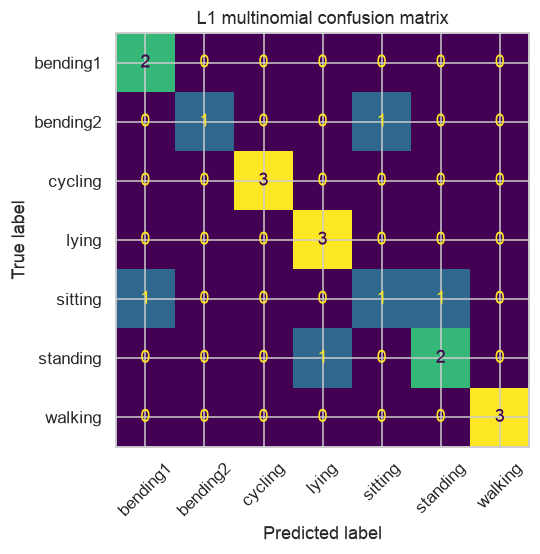

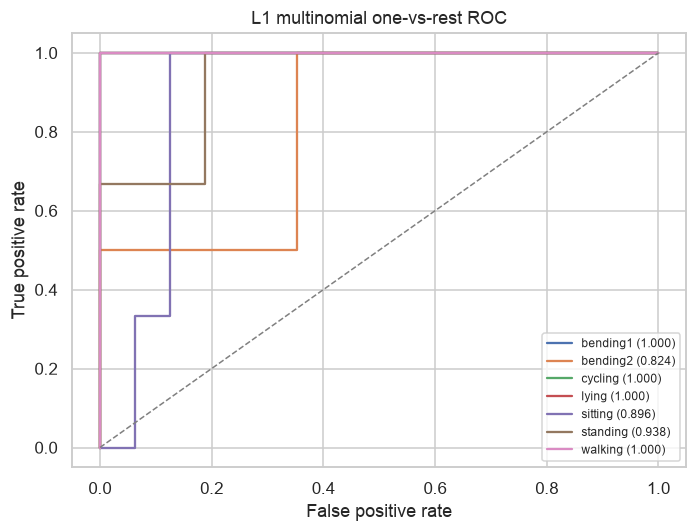

L1 multinomial accuracy: 0.7895
L1 multinomial test error: 0.2105
L1 multinomial macro OvR AUC: 0.9510


In [14]:
activity_labels = np.array(ACTIVITIES)
# bending2 contributes only four training instances, so five stratified folds cannot be built.
activity_folds = list(
    StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE).split(
        feature_cache[1]["train"],
        y_train_act,
    )
)
multiclass_penalties = np.logspace(-2, 2, 9)


def show_multiclass(title, y_true, y_pred, probability, class_names):
    confusion = confusion_matrix(y_true, y_pred, labels=class_names)
    display(pd.DataFrame(confusion, index=class_names, columns=class_names))
    fig, axis = plt.subplots(figsize=(6.5, 5.2))
    ConfusionMatrixDisplay(confusion, display_labels=class_names).plot(
        ax=axis,
        colorbar=False,
        xticks_rotation=45,
    )
    axis.set_title(f"{title} confusion matrix")
    fig.tight_layout()
    plt.show()

    binary_truth = label_binarize(y_true, classes=class_names)
    fig, axis = plt.subplots(figsize=(6.5, 5))
    for class_index, class_name in enumerate(class_names):
        class_false_positive, class_true_positive, _ = roc_curve(
            binary_truth[:, class_index],
            probability[:, class_index],
        )
        class_auc = auc(class_false_positive, class_true_positive)
        axis.plot(class_false_positive, class_true_positive, label=f"{class_name} ({class_auc:.3f})")
    axis.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
    axis.set_xlabel("False positive rate")
    axis.set_ylabel("True positive rate")
    axis.set_title(f"{title} one-vs-rest ROC")
    axis.legend(loc="lower right", fontsize=8)
    fig.tight_layout()
    plt.show()
    macro_auc = roc_auc_score(
        y_true,
        probability,
        multi_class="ovr",
        average="macro",
        labels=class_names,
    )
    test_error = 1.0 - accuracy_score(y_true, y_pred)
    print(f"{title} accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print(f"{title} test error: {test_error:.4f}")
    print(f"{title} macro OvR AUC: {macro_auc:.4f}")
    return test_error


multi_rows = []
best_multi_l = None
best_multi_c = None
best_multi_cv = -1.0
for segment_count in L_VALUES:
    penalty, cv_accuracy = cross_validate_l1(
        segment_count,
        y_train_act,
        activity_folds,
        solver="saga",
        penalties=multiclass_penalties,
        max_iter=800,
    )
    multi_rows.append({"l": segment_count, "C": penalty, "CV accuracy": cv_accuracy})
    print(f"l = {segment_count:2d}  best C = {penalty:.4g}  CV accuracy = {cv_accuracy:.4f}")
    if cv_accuracy > best_multi_cv:
        best_multi_l = segment_count
        best_multi_c = penalty
        best_multi_cv = cv_accuracy

display(pd.DataFrame(multi_rows))
print(
    f"Selected multinomial pair: l = {best_multi_l}, C = {best_multi_c:.4g}, "
    f"CV accuracy = {best_multi_cv:.4f}"
)

multi_scaler = StandardScaler().fit(feature_cache[best_multi_l]["train"])
multi_model = LogisticRegression(
    solver="saga",
    l1_ratio=1.0,
    C=best_multi_c,
    max_iter=2000,
    tol=1e-3,
    random_state=RANDOM_STATE,
)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    multi_model.fit(multi_scaler.transform(feature_cache[best_multi_l]["train"]), y_train_act)
multi_test_probability = multi_model.predict_proba(
    multi_scaler.transform(feature_cache[best_multi_l]["test"])
)
multi_test_prediction = multi_model.predict(multi_scaler.transform(feature_cache[best_multi_l]["test"]))
# predict_proba columns follow multi_model.classes_, so reorder them to ACTIVITIES.
reorder = [list(multi_model.classes_).index(name) for name in activity_labels]
multi_test_error = show_multiclass(
    "L1 multinomial",
    y_test_act,
    multi_test_prediction,
    multi_test_probability[:, reorder],
    activity_labels,
)


#### ii. Naive Bayes

Gaussian naive Bayes and multinomial naive Bayes use the same segmented features. Each method chooses its own \(l\) by the same four-fold stratified accuracy used for the multinomial logistic model. Multinomial naive Bayes requires nonnegative inputs. The mean, standard deviation, and maximum of these RSS series are nonnegative, so no shift is required. The Gaussian model matches continuous features. The multinomial model treats those same numbers as event counts, which is a poorer description of RSS summaries, but it is the prior requested in the question.


Gaussian naive Bayes best l = 1, CV accuracy = 0.9134


,l,CV accuracy
0,1,0.9134
1,2,0.8848
2,3,0.8709
3,4,0.8709
4,5,0.8848
5,6,0.8268
6,7,0.8848
7,8,0.8276
8,9,0.8268
9,10,0.7990


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,1,0,0,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,3,0,0,0
sitting,0,0,0,0,3,0,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3


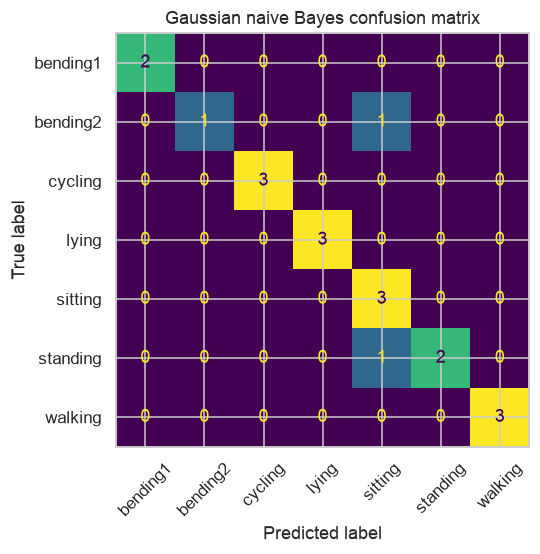

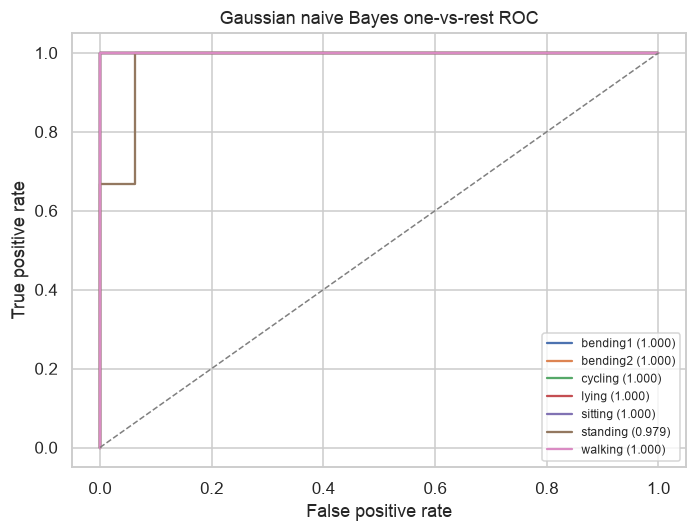

Gaussian naive Bayes accuracy: 0.8947
Gaussian naive Bayes test error: 0.1053
Gaussian naive Bayes macro OvR AUC: 0.9970


Multinomial naive Bayes best l = 4, CV accuracy = 0.8979


,l,CV accuracy
0,1,0.7974
1,2,0.8252
2,3,0.8840
3,4,0.8979
4,5,0.8546
5,6,0.8685
6,7,0.8832
7,8,0.8546
8,9,0.8840
9,10,0.8243


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,2,0,0,0,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,2,1,0,0
sitting,0,0,0,0,2,1,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3


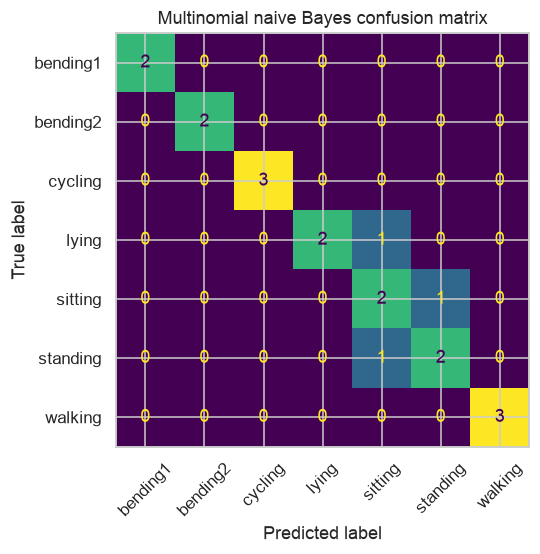

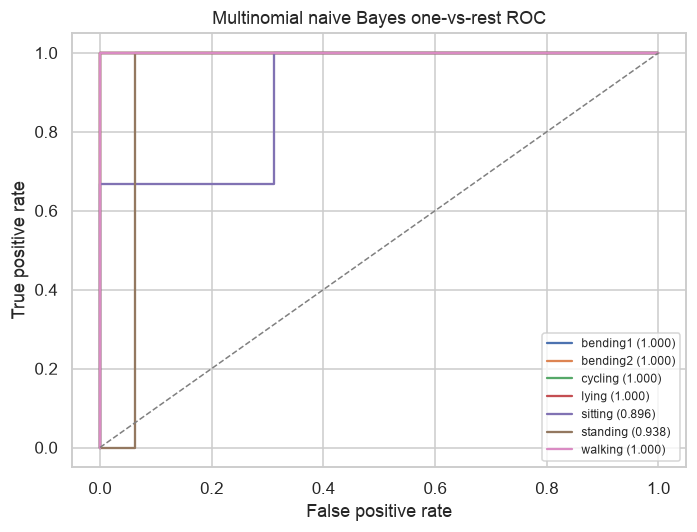

Multinomial naive Bayes accuracy: 0.8421
Multinomial naive Bayes test error: 0.1579
Multinomial naive Bayes macro OvR AUC: 0.9762


In [15]:
def cross_validate_bayes(segment_count, model):
    matrix = feature_cache[segment_count]["train"]
    scores = []
    for train_index, valid_index in activity_folds:
        model.fit(matrix[train_index], y_train_act[train_index])
        predicted = model.predict(matrix[valid_index])
        scores.append(accuracy_score(y_train_act[valid_index], predicted))
    return float(np.mean(scores))


bayes_results = {}
for name, estimator in (("Gaussian", GaussianNB()), ("Multinomial", MultinomialNB())):
    rows = []
    best_segment = None
    best_score = -1.0
    for segment_count in L_VALUES:
        cv_accuracy = cross_validate_bayes(segment_count, estimator)
        rows.append({"l": segment_count, "CV accuracy": cv_accuracy})
        if cv_accuracy > best_score:
            best_segment = segment_count
            best_score = cv_accuracy
    print(f"{name} naive Bayes best l = {best_segment}, CV accuracy = {best_score:.4f}")
    display(pd.DataFrame(rows))
    estimator.fit(feature_cache[best_segment]["train"], y_train_act)
    probability = estimator.predict_proba(feature_cache[best_segment]["test"])
    prediction = estimator.predict(feature_cache[best_segment]["test"])
    reorder = [list(estimator.classes_).index(label) for label in activity_labels]
    test_error = show_multiclass(
        f"{name} naive Bayes",
        y_test_act,
        prediction,
        probability[:, reorder],
        activity_labels,
    )
    bayes_results[name] = {"l": best_segment, "cv": best_score, "test_error": test_error}


#### iii. Comparison


In [16]:
method_errors = {
    "L1 multinomial logistic regression": multi_test_error,
    "Gaussian naive Bayes": bayes_results["Gaussian"]["test_error"],
    "Multinomial naive Bayes": bayes_results["Multinomial"]["test_error"],
}
comparison = pd.DataFrame(
    {"test error": pd.Series(method_errors)}
).sort_values("test error")
display(comparison)
best_method = comparison.index[0]
print(
    f"{best_method} has the lowest test error, so it is the better multiclass method on this split."
)
print(
    "Gaussian naive Bayes is the more appropriate of the two naive Bayes models "
    "because the features are continuous. L1 multinomial logistic regression can "
    "still win when the classes need a linear decision boundary that the independence "
    "assumption in naive Bayes misses."
)


,test error
Gaussian naive Bayes,0.1053
Multinomial naive Bayes,0.1579
L1 multinomial logistic regression,0.2105


Gaussian naive Bayes has the lowest test error, so it is the better multiclass method on this split.
Gaussian naive Bayes is the more appropriate of the two naive Bayes models because the features are continuous. L1 multinomial logistic regression can still win when the classes need a linear decision boundary that the independence assumption in naive Bayes misses.


## 3. ISLR 4.8.3

There is one predictor, and an observation from class \(k\) follows \(X \sim N(\mu_k, \sigma_k^2)\). The Bayes classifier assigns \(x\) to the class with the largest

\[
\delta_k(x) = -\frac{(x-\mu_k)^2}{2\sigma_k^2} - \log \sigma_k + \log \pi_k.
\]

Expanding the square gives

\[
\delta_k(x) = -\frac{1}{2\sigma_k^2} x^2 + \frac{\mu_k}{\sigma_k^2} x - \frac{\mu_k^2}{2\sigma_k^2} - \log \sigma_k + \log \pi_k.
\]

The coefficient of \(x^2\) depends on \(k\) whenever the class variances differ. The boundary \(\delta_k(x) = \delta_j(x)\) is therefore a quadratic equation in \(x\), not a straight line. The Bayes classifier is quadratic. It would be linear only if every class had the same variance, because then the \(x^2\) terms would cancel when two discriminants are set equal.


## 4. ISLR 4.8.7

Last year's percent profit is \(X\). Companies that issued a dividend have mean 10, companies that did not have mean 0, and both groups have variance 36. The prior probability of a dividend is 0.8. Because the two variances are equal, the normal density contributes only the exponential term. For \(X = 4\),

\[
P(Y=\text{Yes}\mid X=4)
= \frac{0.8 \exp\left(-(4-10)^2 / 72\right)}
{0.8 \exp\left(-(4-10)^2 / 72\right) + 0.2 \exp\left(-(4-0)^2 / 72\right)}.
\]


In [17]:
variance = 36.0
likelihood_yes = np.exp(-((4 - 10) ** 2) / (2 * variance))
likelihood_no = np.exp(-((4 - 0) ** 2) / (2 * variance))
posterior_yes = (0.8 * likelihood_yes) / (0.8 * likelihood_yes + 0.2 * likelihood_no)
print(f"Likelihood contribution, dividend: {likelihood_yes:.6f}")
print(f"Likelihood contribution, no dividend: {likelihood_no:.6f}")
print(f"P(dividend | X = 4) = {posterior_yes:.4f}")


Likelihood contribution, dividend: 0.606531
Likelihood contribution, no dividend: 0.800737
P(dividend | X = 4) = 0.7519
